# Assignment Module 2: Pet Classification

The goal of this assignment is to implement a neural network that classifies images of 37 breeds of cats and dogs from the [Oxford-IIIT-Pet dataset](https://www.robots.ox.ac.uk/~vgg/data/pets/). The assignment is divided into two parts: first, you will be asked to implement from scratch your own neural network for image classification; then, you will fine-tune a pretrained network provided by PyTorch.

## Dataset

The following cells contain the code to download and access the dataset you will be using in this assignment. Note that, although this dataset features each and every image from [Oxford-IIIT-Pet](https://www.robots.ox.ac.uk/~vgg/data/pets/), it uses a different train-val-test split than the original authors.

In [ ]:
# !git clone https://github.com/CVLAB-Unibo/ipcv-assignment-2.git

In [8]:
from pathlib import Path
from PIL import Image
from torch import Tensor
from torch.utils.data import Dataset
from typing import List, Tuple

In [9]:
class OxfordPetDataset(Dataset):
    def __init__(self, split: str, transform=None) -> None:
        super().__init__()

        self.root = Path("ipcv-assignment-2") / "dataset"
        self.split = split
        self.names, self.labels = self._get_names_and_labels()
        self.transform = transform

    def __len__(self) -> int:
        return len(self.labels)

    def __getitem__(self, idx) -> Tuple[Tensor, int]:
        img_path = self.root / "images" / f"{self.names[idx]}.jpg"
        img = Image.open(img_path).convert("RGB")
        label = self.labels[idx]
        
        if self.transform:
            img = self.transform(img)

        return img, label
    
    def get_num_classes(self) -> int:
        return max(self.labels) + 1

    def _get_names_and_labels(self) -> Tuple[List[str], List[int]]:
        names = []
        labels = []

        with open(self.root / "annotations" / f"{self.split}.txt") as f:
            for line in f:
                name, label = line.replace("\n", "").split(" ")
                names.append(name), 
                labels.append(int(label) - 1)

        return names, labels

## Part 1: design your own network

Your goal is to implement a convolutional neural network for image classification and train it from scratch on `OxfordPetDataset`. You should consider yourselves satisfied once you obtain a classification accuracy on the test split of ~60%. You are free to achieve this however you want, except for a few rules you must follow:

- Compile this notebook by displaying the results obtained by the best model you found throughout your experimentation; then show how, by removing some of its components, its performance drops. In other words, do an *ablation study* to prove that your design choices have a positive impact on the final result.

- Do not instantiate an off-the-self PyTorch network. Instead, construct your network as a composition of existing PyTorch layers. In more concrete terms, you can use e.g. `torch.nn.Linear`, but you cannot use e.g. `torchvision.models.alexnet`.

- Show your results and ablations with plots, tables, images, etc. — the clearer, the better.

Don't be too concerned with your model performance: the ~60% is just to give you an idea of when to stop. Keep in mind that a thoroughly justified model with lower accuracy will be rewarded more points than a poorly experimentally validated model with higher accuracy.

In [10]:
import torch
def get_device():
    if torch.backends.mps.is_available():
        device = "mps"
    elif torch.cuda.is_available():
        device = "cuda"
    else:
        device = "cpu"
    return device

In [11]:
from torch.nn import Module, Linear, ReLU

class ModelFC(Module):
    def __init__(self, num_classes: int, hidden_layers: int, input_size: int) -> None:
        super().__init__()
        self.hidden_layers = hidden_layers
        self.input_size = input_size
        self.fc = Linear(input_size, input_size//4)
        self.out = Linear(input_size//4, num_classes)
        self.relu = ReLU()

    def forward(self, x: Tensor) -> Tensor:
        x = x.view(x.size(0), -1)  # Flatten the input
        x = self.fc(x)
        x = self.relu(x)  # Apply ReLU activation
        return self.out(x)

In [12]:
from torchvision import transforms


# Visualize the dataset
transform = transforms.Compose([
    transforms.Resize((32,32)), # ricordiamoci di aumentare risoluzione se fa schifo
    transforms.ToTensor()
])

train = OxfordPetDataset(split="train", transform=transform)
validation = OxfordPetDataset(split="val", transform=transform)
test = OxfordPetDataset(split="test", transform=transform)
print(f"Train set: {len(train)} images, {train.get_num_classes()} classes")
print(f"Validation set: {len(validation)} images, {validation.get_num_classes()} classes")
print(f"Test set: {len(test)} images, {test.get_num_classes()} classes")

Train set: 3669 images, 37 classes
Validation set: 1834 images, 37 classes
Test set: 1846 images, 37 classes


In [13]:
from torch.utils.data import DataLoader

batch_size = 2

# Load some images
train_loader = DataLoader(train, batch_size=batch_size, shuffle=True)
validation_loader = DataLoader(validation, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test, batch_size=batch_size, shuffle=False)


In [14]:
from torch.nn.functional import cross_entropy
from torch.optim import Adam
from tqdm import tqdm
num_classes = 37
epochs = 100
input_size = 3 * 32 * 32  # 3 channels, 32x32 pixels

device = get_device()
print(f"Using device: {device}")

model = ModelFC(num_classes, hidden_layers=1, input_size=input_size).to(device)

criterion = cross_entropy
optimizer = Adam(model.parameters(), lr=0.01)

losses = []
for epoch in range(epochs):
    epoch_loss = 0.0

    for imgs, labels in tqdm(train_loader):

        imgs = imgs.to(device)
        labels = labels.to(device)

        preds = model(imgs)
        
        # compute gradients
        loss = criterion(preds, labels) 
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        epoch_loss += loss.item()
    
    epoch_loss /= len(train_loader)
    losses.append(epoch_loss)
    print(f"Epoch {epoch + 1}/{epochs}, Loss: {epoch_loss:.4f}")
        


Using device: mps


  0%|          | 0/1835 [00:00<?, ?it/s]


RuntimeError: element 0 of tensors does not require grad and does not have a grad_fn

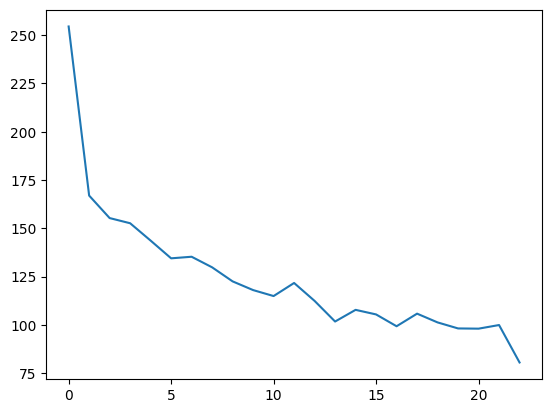

In [21]:
import matplotlib.pyplot as plt
plt.plot(range(0, 23), losses)

In [22]:
model.eval()
correct = 0
total = 0
with torch.no_grad():
    for imgs, labels in tqdm(test_loader):
        imgs = imgs.to(device)
        labels = labels.to(device)

        preds = model(imgs)
        _, predicted = torch.max(preds, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()
accuracy = correct / total
print(f"Test Accuracy: {accuracy:.4f}")


100%|██████████| 116/116 [00:04<00:00, 23.83it/s]

Test Accuracy: 0.0720


## Part 2: fine-tune an existing network

Your goal is to fine-tune a pretrained ResNet-18 model on `OxfordPetDataset`. Use the implementation provided by PyTorch, i.e. the opposite of part 1. Specifically, use the PyTorch ResNet-18 model pretrained on ImageNet-1K (V1). Divide your fine-tuning into two parts:

2A. First, fine-tune the ResNet-18 with the same training hyperparameters you used for your best model in part 1.

2B. Then, tweak the training hyperparameters in order to increase the accuracy on the test split. Justify your choices by analyzing the training plots and/or citing sources that guided you in your decisions — papers, blog posts, YouTube videos, or whatever else you may find useful. You should consider yourselves satisfied once you obtain a classification accuracy on the test split of ~90%.